In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

KNN

In [5]:
# Generate the dataset (everyone uses the same seed for consistency)
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)

In [6]:
def knn_predict(X_train, y_train, X_test, y_test, k, distance_func):
  # Keep track of the current k nearest neighbors and their class values
  neighbors = []  # list of (distance, class_label)

  # Go through each training record and compute the distance to X_test (use ord=distance_func)
  for i in range(len(X_train)):
    # Calculate the distance between the current record and the test record
    dist = np.linalg.norm(X_train[i] - X_test, ord=distance_func)
    # Add it in by default if not up to the top
    # We sort it each time so we can easily remove the last one if there is a shorter neighbor we find
    if len(neighbors) < k:
      neighbors.append((dist, y_train[i]))
      neighbors.sort(key=lambda x: x[0])
    elif dist < neighbors[-1][0]:
      neighbors[-1] = (dist, y_train[i])
      neighbors.sort(key=lambda x: x[0])

  # At the end, return the most common class, with a tie being broken by the classes that are closer to the predicted class
  class_counts = Counter([label for _, label in neighbors])
  max_count = max(class_counts.values())
  tied_classes = [cls for cls, count in class_counts.items() if count == max_count]
  if len(tied_classes) == 1:
    return tied_classes[0]
  
  # Break tie by average distance of each tied class
  avg_distances = {}
  for cls in tied_classes:
    dists = [d for d, label in neighbors if label == cls]
    avg_distances[cls] = np.mean(dists)

  return min(avg_distances.items(), key=lambda x: x[1])[0]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

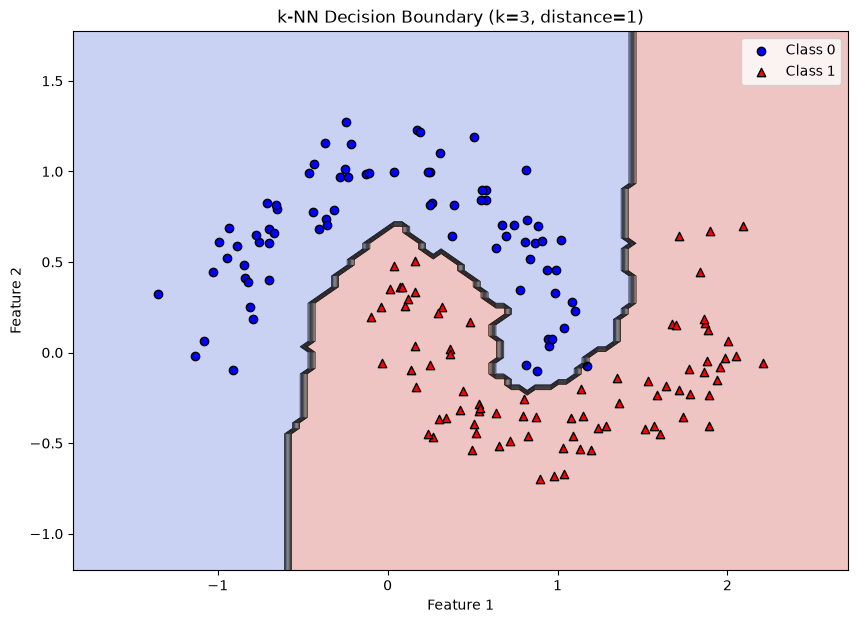

In [8]:
def plot_knn_decision_boundary(X_train, y_train, k, distance_func, resolution=100):
  # Find the boundaries for the graph (add some padding for easier visualization)
  x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
  y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
  xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolution),
                        np.linspace(y_min, y_max, resolution))

  # Predict class for each point on the grid
  grid_points = np.c_[xx.ravel(), yy.ravel()]
  predictions = np.array([knn_predict(X_train, y_train, point, None, k, distance_func)
                          for point in grid_points])
  predictions = predictions.reshape(xx.shape)

  # Plot decision boundary on the graph using the calculated points
  plt.figure(figsize=(10, 7))
  plt.contourf(xx, yy, predictions, alpha=0.3, cmap='coolwarm')
  plt.contour(xx, yy, predictions, colors='k', linewidths=0.5)

  # Plot training points on the graph using different markers/colors for each
  plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
              c='blue', marker='o', edgecolors='k', label='Class 0')
  plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
              c='red', marker='^', edgecolors='k', label='Class 1')

  plt.xlabel('Feature 1')
  plt.ylabel('Feature 2')
  plt.title(f'k-NN Decision Boundary (k={k}, distance={distance_func})')
  plt.legend()
  plt.show()

plot_knn_decision_boundary(X_train, y_train, k=3, distance_func=1)

In [9]:
def compute_knn_errors(X, y, k, distance_func):
  n = len(X)

  # Training error: Use the full dataset as the training set to predict
  train_misses = 0
  for i in range(n):
    pred = knn_predict(X, y, X[i], y[i], k, distance_func)
    if pred != y[i]:
      train_misses += 1
  train_error = train_misses / n

  # Test error: LOOCV
  test_misses = 0
  for i in range(n):
    # Use record i as testing, and all others as training
    X_train = np.delete(X, i, axis=0)
    y_train = np.delete(y, i)
    pred = knn_predict(X_train, y_train, X[i], y[i], k, distance_func)
    if pred != y[i]:
      test_misses += 1
  test_error = test_misses / n

  print(f"k={k}, distance={distance_func}")
  print(f"  Training error: {train_error:.4f} ({train_misses}/{n})")
  print(f"  Test error (LOOCV): {test_error:.4f} ({test_misses}/{n})")
  return train_error, test_error

compute_knn_errors(X, y, k=3, distance_func=1)

k=3, distance=1
  Training error: 0.0100 (2/200)
  Test error (LOOCV): 0.0100 (2/200)


(0.01, 0.01)

Neural Network

In [ ]:
def train_perceptron(training_record, learning_rate, w1, w2, b):
  x1, x2, y = training_record
  z = w1 * x1 + w2 * x2 + b
  pred = 1 if z >= 0 else 0
  
  # Update weights and bias using perceptron training rule
  w1 += learning_rate * (y - pred) * x1
  w2 += learning_rate * (y - pred) * x2
  b += learning_rate * (y - pred)
  return w1, w2, b

In [10]:
def train_neuron(training_record, learning_rate, w, b, cost_derivative, activation_derivative):
  x, y = training_record
  pred = w * x + b

  # Chain rule: dC/dw = cost_derivative(z, y) * activation_derivative(z) * x
  delta = cost_derivative(pred, y) * activation_derivative(pred)

  # Update weight and bias
  w -= learning_rate * delta * x
  b -= learning_rate * delta
  return w, b